<a href="https://colab.research.google.com/github/JhaAKumar/DataProcessing/blob/main/IAEA_ICTP_Workshop_Dataprocessingpipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IAEA-ICTP AI Workshop - Lab 1-1: Data Cleaning and Processing**

*Editor: Ashish Jha*

In this lab, we’ll explore the foundational steps of data cleaning and processing, essential for preparing raw data for machine learning models. Using Radiomics data common challenges in data preprocessing, including handling missing values, normalizing data, and harmonization.

# Explanation of the Notebook Pipeline

This notebook demonstrates a structured machine learning workflow for medical imaging (Radiomics) data. It addresses critical data processing challenges including handling missing data, standardization, and correcting acquisition site differences (batch effects) using statistical and deep learning-based harmonization techniques.


###  Environment Setup and Library Imports
- **Purpose**: Initializes the workspace.
- **Key Tasks**:
  - Imports fundamental data manipulation libraries (`numpy`, `pandas`).
  - Imports visualization tools (`matplotlib.pyplot`, `seaborn`) to examine feature distributions.
  - Imports utility functions for model evaluation and dataset splitting from `sklearn`.
  - Configures a clean, consistent seaborn visualization style.

In [57]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# Configure seaborn theme
sns.set_theme(style="whitegrid", font_scale=1.0)

# To display a single plot/image, use a single ax:
# fig, ax = plt.subplots(figsize=(10, 6))
# sns.barplot(..., ax=ax)

###  Data Loading
- **Purpose**: Retrieves the raw dataset from a remote GitHub repository.
- **Key Tasks**:
  - Reads `_radiomics_missing_data.csv` into a pandas DataFrame (`df`).
  - Displays the shape (6000 rows × 29 columns) and preview of the data, highlighting missing values (`NaN`), different imaging sites (`Site_A` to `Site_D`), patient demographics (`Age`, `Sex`), and the target variable (`Outcome`).


In [58]:
df = pd.read_csv("https://raw.githubusercontent.com/JhaAKumar/DataProcessing/main/_radiomics_missing_data.csv")
df

,Patient_ID,RadFeat_01,RadFeat_02,RadFeat_03,RadFeat_04,RadFeat_05,RadFeat_06,RadFeat_07,RadFeat_08,RadFeat_09,...,RadFeat_19,RadFeat_20,RadFeat_21,RadFeat_22,RadFeat_23,RadFeat_24,Site,Age,Sex,Outcome
0,SYN00001,-0.710300,1.110960,0.165702,1.207406,0.772339,1.306985,0.082650,-0.952050,0.935772,...,NaN,0.596450,1.504907,NaN,1.663392,0.419686,Site_C,49.6,M,0
1,SYN00002,-1.359971,-0.332197,NaN,0.619911,1.353593,0.278686,-1.579345,NaN,NaN,...,-1.054586,-1.512560,-0.680821,-0.886107,NaN,-0.848084,Site_B,66.3,F,0
2,SYN00003,2.776007,1.187369,1.208407,3.477567,-0.978677,3.434757,1.408356,1.806880,2.873953,...,-0.786383,NaN,NaN,0.812746,-1.010789,0.476984,Site_D,54.3,M,1
3,SYN00004,2.209068,-0.443841,1.188933,-3.654440,-0.531119,-2.277551,1.393303,1.640300,-0.473327,...,0.000943,3.417426,1.073439,-0.643285,NaN,1.513763,Site_C,NaN,F,0
4,SYN00005,-1.050653,-0.774588,-2.148712,-2.589994,-1.635483,NaN,-1.046079,NaN,0.830259,...,0.472185,-1.620359,-0.383194,-2.839723,-0.786975,-1.766213,Site_A,57.8,F,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,SYN05996,0.528033,-0.260569,NaN,1.701071,NaN,-0.651945,1.804486,1.600738,-2.394299,...,0.236205,-0.910193,-1.079612,0.164719,-0.338339,-1.784526,Site_B,62.3,M,1
5996,SYN05997,-0.310133,1.213637,-0.617917,-0.133536,4.289764,NaN,NaN,0.509630,0.905486,...,NaN,-0.795060,1.058550,-0.269455,1.737079,-1.582175,Site_C,62.3,M,0
5997,SYN05998,NaN,3.656496,3.655234,2.855558,5.725276,0.424451,1.820251,2.641864,0.286400,...,3.781461,1.522970,1.732175,3.698987,2.713452,NaN,Site_D,63.3,F,1
5998,SYN05999,0.587728,NaN,0.650223,0.166146,0.023363,0.120684,1.154890,2.523380,5.108448,...,4.235219,NaN,1.464635,-0.280603,1.968485,1.603115,Site_D,NaN,F,0


### Exploratory Data Analysis - Missing Data
- **Purpose**: Analyzes the prevalence and pattern of missing values across features.
- **Key Tasks**:
  - Computes the percentage of missing values for each column.
  - Filters columns containing missing values and displays them on a descending horizontal bar plot.
  - Shows that most radiomic features are missing roughly **14% to 15%** of their data, while demographics (`Age`, `Sex`) are missing around **12% to 13%**.


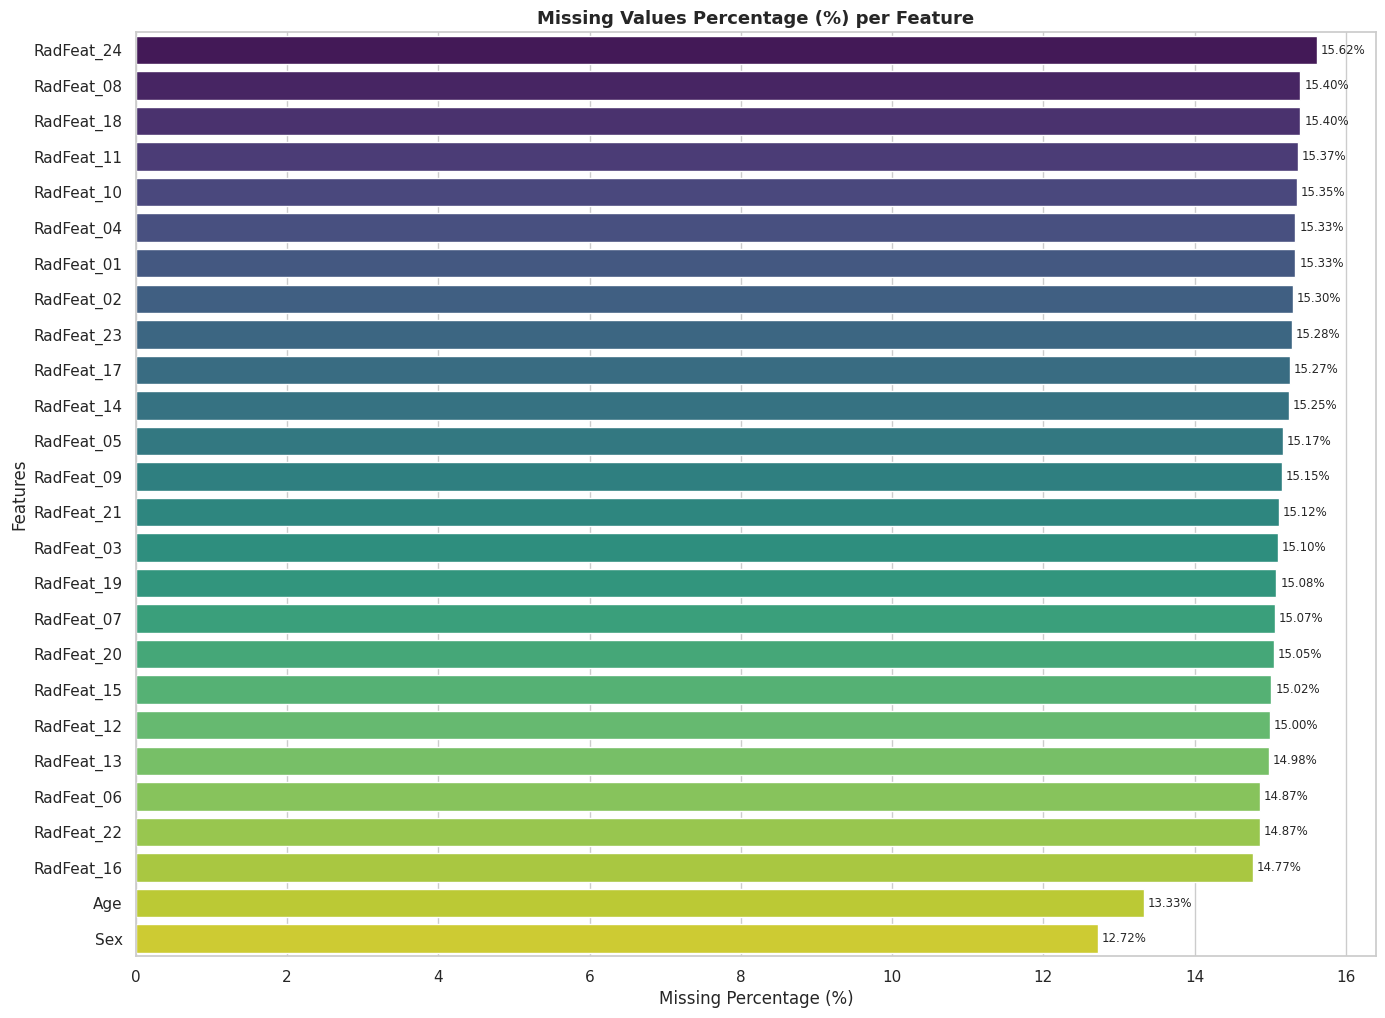

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns
# 2. Set overall visualization style
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, ax = plt.subplots(figsize=(16, 12))
# -------------------------------------------------------------
# Panel 1: Missing Values Percentage per Column
# -------------------------------------------------------------
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index,
    hue=missing_pct.index,
    legend=False,
    ax=ax,
    palette="viridis",
)
ax.set_title(
    "Missing Values Percentage (%) per Feature", fontsize=13, fontweight="bold"
)
ax.set_xlabel("Missing Percentage (%)")
ax.set_ylabel("Features")

# Annotate exact percentage labels on the bars
for idx, val in enumerate(missing_pct.values):
    ax.text(val + 0.05, idx, f"{val:.2f}%", va="center", fontsize=8.5)


### Visualizing Site Batch Effects
- **Purpose**: Checks for scanner-specific or site-specific data shifts (batch effects).
- **Key Tasks**:
  - Selects a sample subset of features (`RadFeat_01` to `RadFeat_04`) and melts the DataFrame to prepare it for grouping.
  - Generates grouped boxplots showing feature values split by acquisition site (`Site_A` through `Site_D`).
  - **Observation**: Clear variations in feature means, medians, and ranges are visible across sites (e.g., `Site_D` consistently exhibits higher feature values than `Site_A`), indicating a strong batch effect.




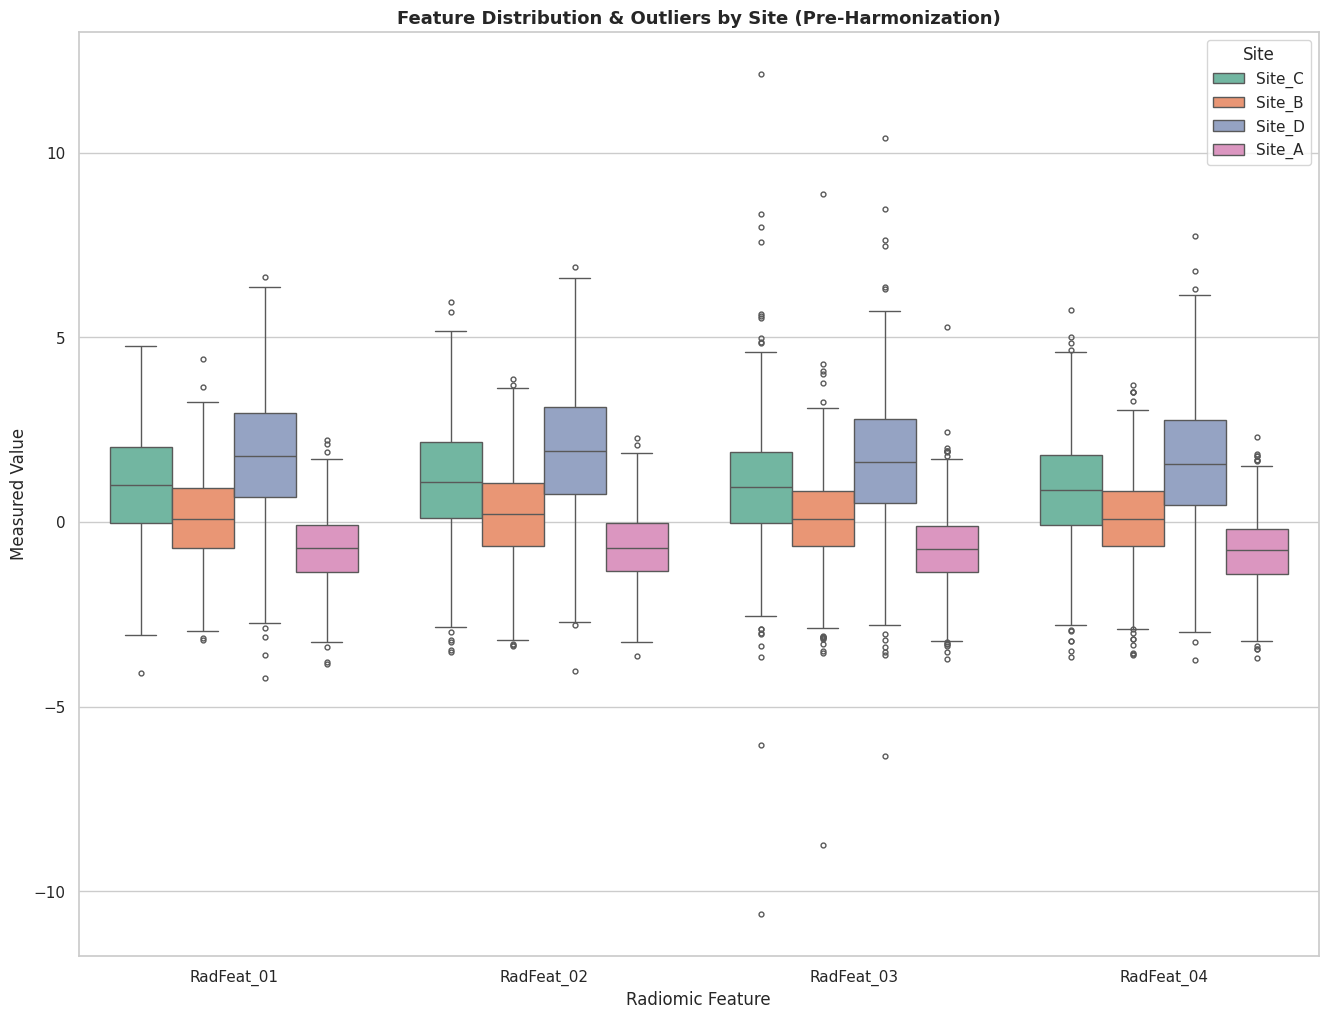

In [60]:
# 2. Set overall visualization style
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, ax = plt.subplots(figsize=(16, 12))

# -------------------------------------------------------------
# Panel 2: Boxplots of Radiomic Features Grouped by Site (Batch Effect & Outliers)
# -------------------------------------------------------------

sample_features = ["RadFeat_01", "RadFeat_02", "RadFeat_03", "RadFeat_04"]
melted_df = pd.melt(
    df,
    id_vars=["Site"],
    value_vars=sample_features,
    var_name="Feature",
    value_name="Value",
)

sns.boxplot(
    data=melted_df,
    x="Feature",
    y="Value",
    hue="Site",
    ax=ax,
    palette="Set2",
    fliersize=3.5,
)
ax.set_title(
    "Feature Distribution & Outliers by Site (Pre-Harmonization)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Radiomic Feature")
ax.set_ylabel("Measured Value")
ax.legend(title="Site", loc="upper right")

### Target Distribution Across Sites
- **Purpose**: Checks if the target label (`Outcome`) is confounded by or correlated with the acquisition site.
- **Key Tasks**:
  - Generates a stacked bar plot of patient counts for positive vs. negative outcomes grouped by site.
  - **Observation**: The balance between class `0` (negative) and class `1` (positive) is highly consistent across all sites. This tells us the site-specific distribution shifts observed in Cell 4 represent non-biological batch effects, not true differences in clinical outcomes.

---

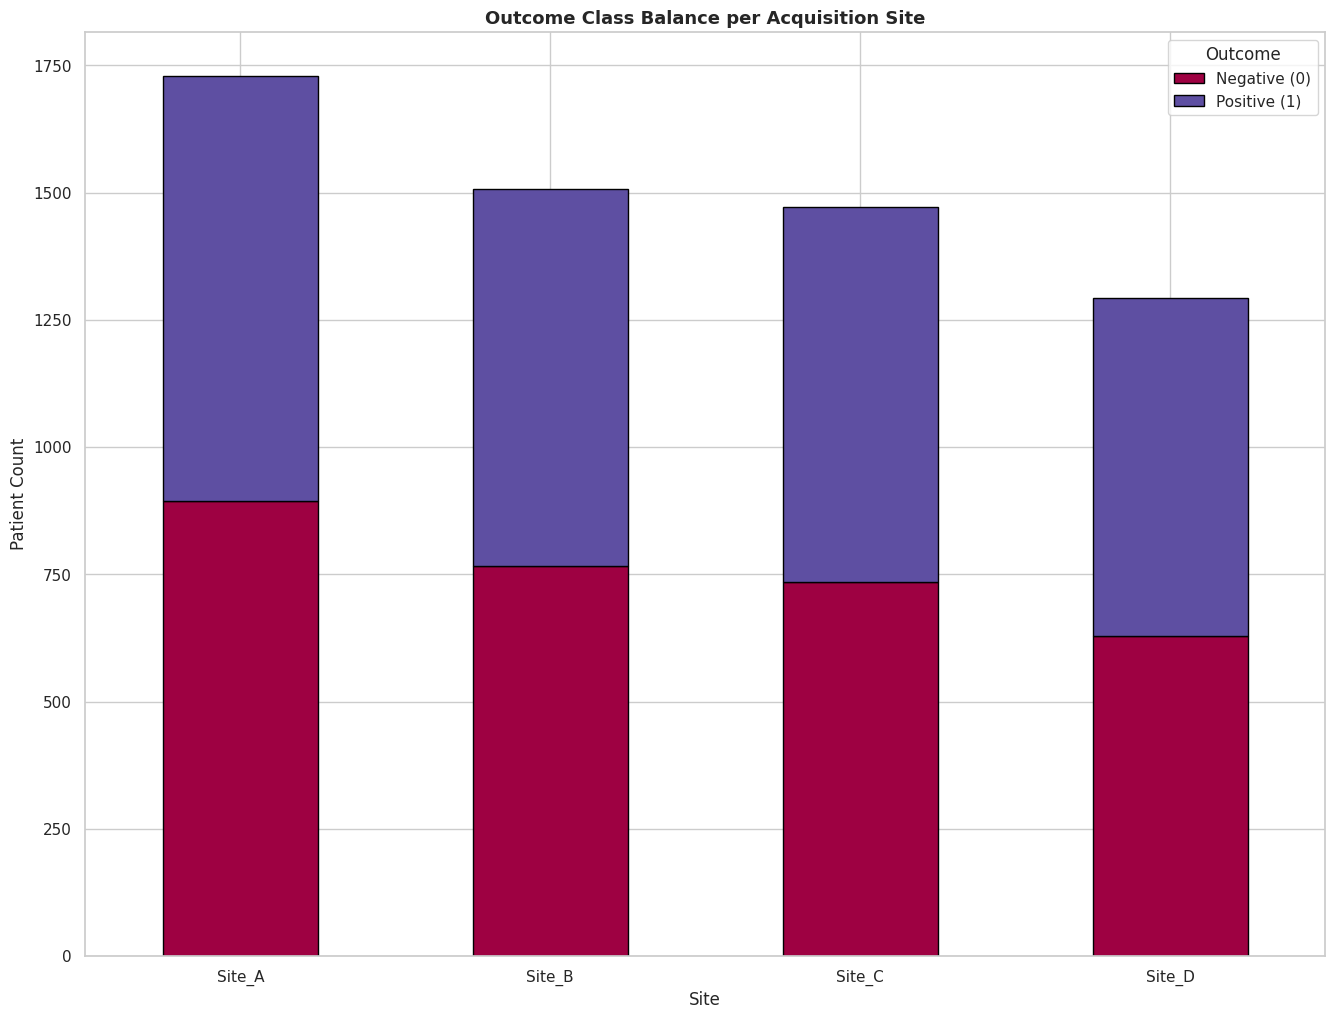

In [61]:
# 2. Set overall visualization style
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, ax = plt.subplots(figsize=(16, 12))
# -------------------------------------------------------------
# Panel 3: Outcome Distribution Across Scanner Sites
# -------------------------------------------------------------
site_outcome = df.groupby(["Site", "Outcome"]).size().unstack()
site_outcome.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    colormap="Spectral",
    edgecolor="black",
)
ax.set_title(
    "Outcome Class Balance per Acquisition Site", fontsize=13, fontweight="bold"
)
ax.set_xlabel("Site")
ax.set_ylabel("Patient Count")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Outcome", labels=["Negative (0)", "Positive (1)"])

###Feature Correlation Heatmap
- **Purpose**: Evaluates collinearity among features.
- **Key Tasks**:
  - Generates a correlation heatmap among the first 10 radiomic features, age, and clinical outcome.
  - **Observation**: Several radiomic features exhibit moderate-to-high correlation with each other, which is typical in clinical radiomics studies.

---

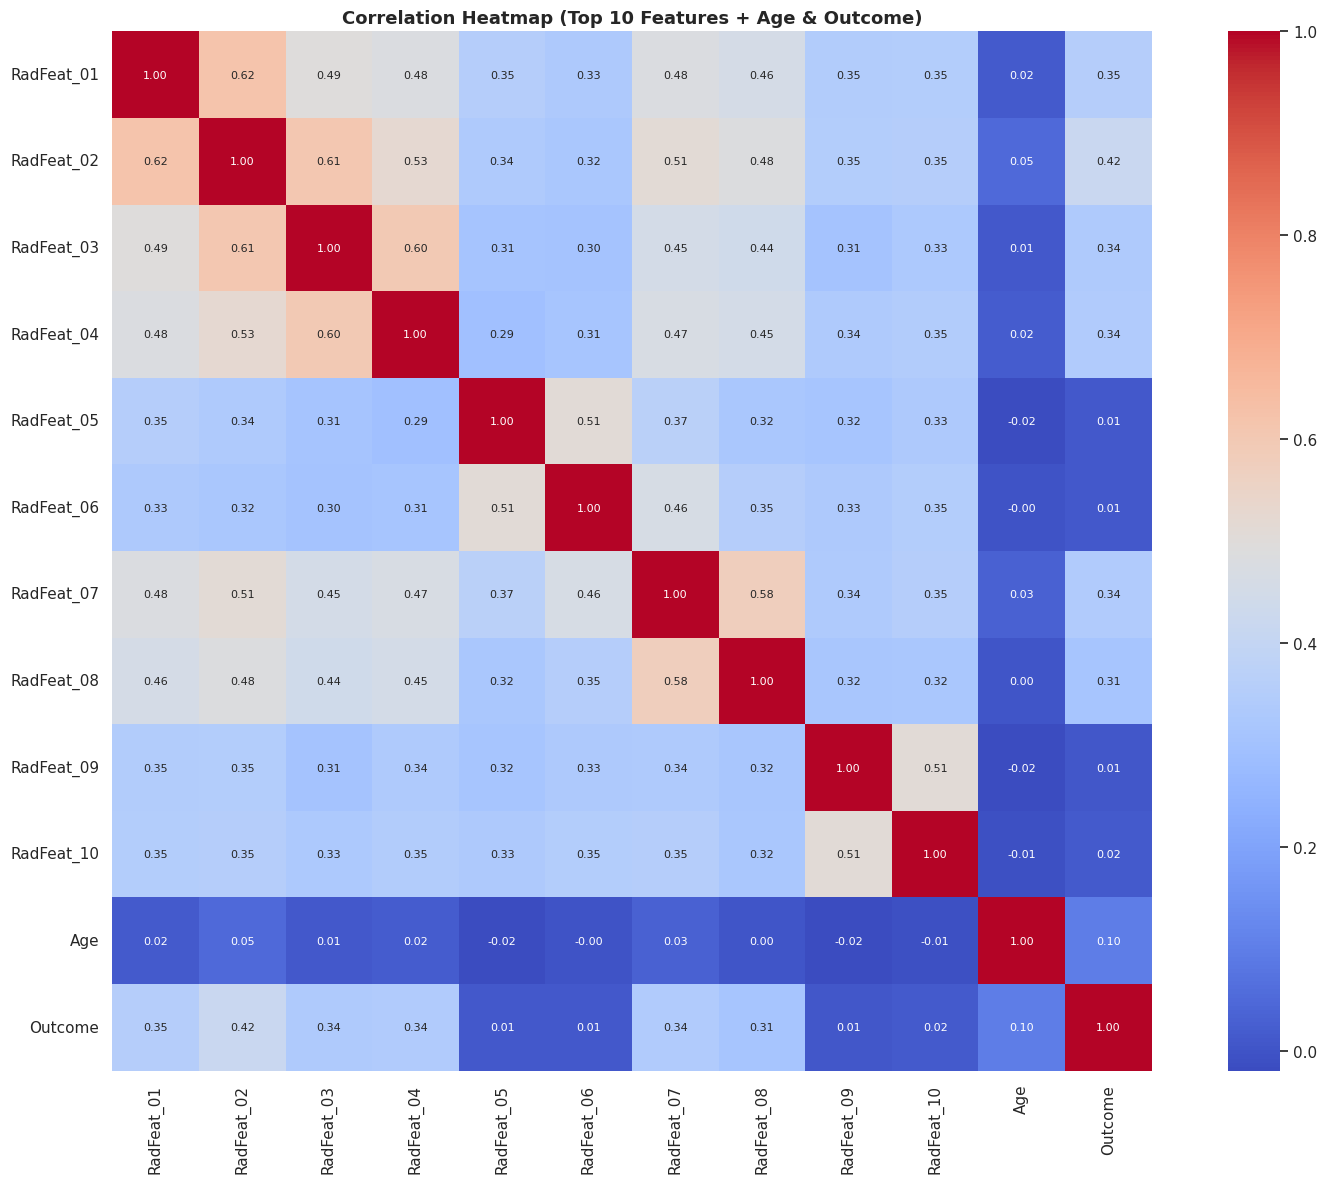

In [62]:
# 2. Set overall visualization style
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, ax = plt.subplots(figsize=(16, 12))
# -------------------------------------------------------------
# Panel 4: Correlation Matrix Heatmap
# -------------------------------------------------------------
top_features = [f"RadFeat_{i:02d}" for i in range(1, 11)] + ["Age", "Outcome"]
corr_matrix = df[top_features].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    ax=ax,
    square=True,
    annot_kws={"size": 8},
)
ax.set_title(
    "Correlation Heatmap (Top 10 Features + Age & Outcome)",
    fontsize=13,
    fontweight="bold",
)

# 3. Layout adjustment and export
plt.tight_layout()
plt.savefig("radiomics_eda_dashboard.png", dpi=300)
plt.show()

###Consolidated EDA Dashboard
- **Purpose**: Synthesizes the individual plots into a single, high-resolution dashboard file.
- **Key Tasks**:
  - Creates a $2 \times 2$ grid containing all previous plots (missing values, boxplots, stacked class bars, and the heatmap).
  - Saves the resulting dashboard as a high-density image file (`radiomics_eda_dashboard.png`) for reporting.

---

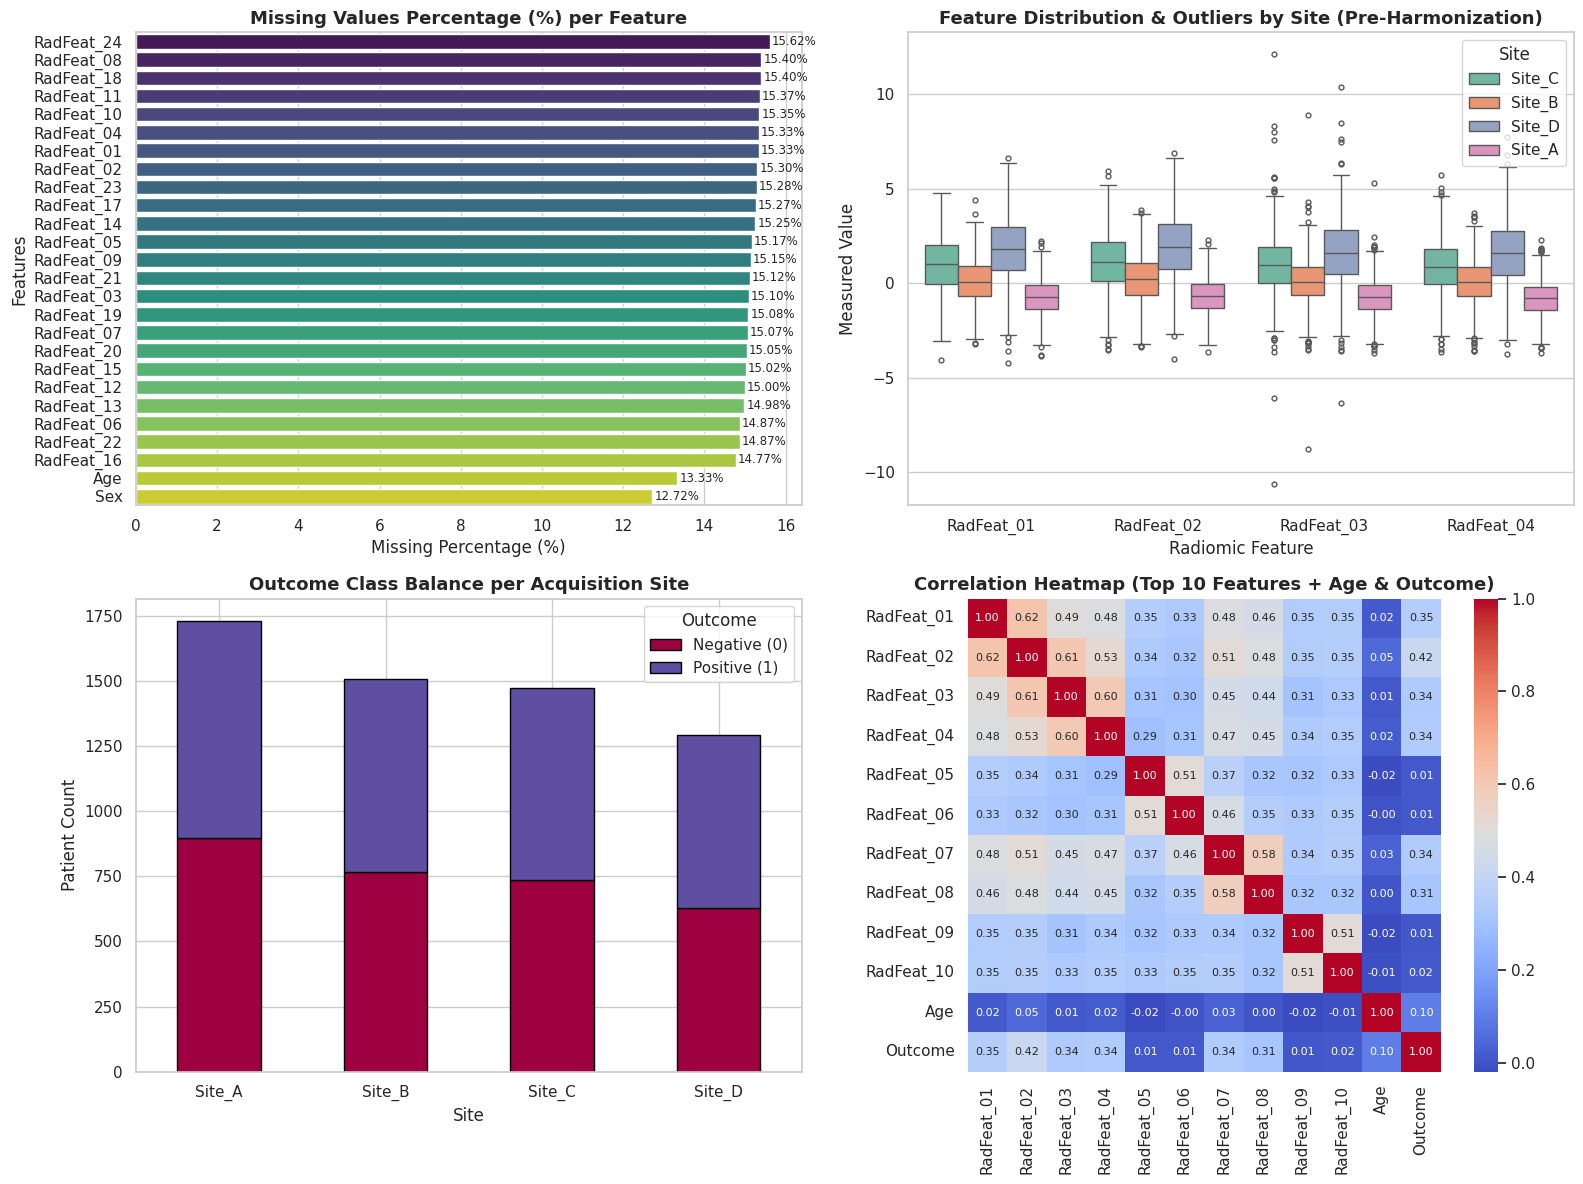

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Set overall visualization style
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
# -------------------------------------------------------------
# Panel 1: Missing Values Percentage per Column
# -------------------------------------------------------------
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

sns.barplot(
    x=missing_pct.values,
    y=missing_pct.index,
    hue=missing_pct.index,
    legend=False,
    ax=axes[0, 0],
    palette="viridis",
)
axes[0, 0].set_title(
    "Missing Values Percentage (%) per Feature", fontsize=13, fontweight="bold"
)
axes[0, 0].set_xlabel("Missing Percentage (%)")
axes[0, 0].set_ylabel("Features")

# Annotate exact percentage labels on the bars
for idx, val in enumerate(missing_pct.values):
    axes[0, 0].text(val + 0.05, idx, f"{val:.2f}%", va="center", fontsize=8.5)

# -------------------------------------------------------------
# Panel 2: Boxplots of Radiomic Features Grouped by Site (Batch Effect & Outliers)
# -------------------------------------------------------------
sample_features = ["RadFeat_01", "RadFeat_02", "RadFeat_03", "RadFeat_04"]
melted_df = pd.melt(
    df,
    id_vars=["Site"],
    value_vars=sample_features,
    var_name="Feature",
    value_name="Value",
)

sns.boxplot(
    data=melted_df,
    x="Feature",
    y="Value",
    hue="Site",
    ax=axes[0, 1],
    palette="Set2",
    fliersize=3.5,
)
axes[0, 1].set_title(
    "Feature Distribution & Outliers by Site (Pre-Harmonization)",
    fontsize=13,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Radiomic Feature")
axes[0, 1].set_ylabel("Measured Value")
axes[0, 1].legend(title="Site", loc="upper right")

# -------------------------------------------------------------
# Panel 3: Outcome Distribution Across Scanner Sites
# -------------------------------------------------------------
site_outcome = df.groupby(["Site", "Outcome"]).size().unstack()
site_outcome.plot(
    kind="bar",
    stacked=True,
    ax=axes[1, 0],
    colormap="Spectral",
    edgecolor="black",
)
axes[1, 0].set_title(
    "Outcome Class Balance per Acquisition Site", fontsize=13, fontweight="bold"
)
axes[1, 0].set_xlabel("Site")
axes[1, 0].set_ylabel("Patient Count")
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].legend(title="Outcome", labels=["Negative (0)", "Positive (1)"])

# -------------------------------------------------------------
# Panel 4: Correlation Matrix Heatmap
# -------------------------------------------------------------
top_features = [f"RadFeat_{i:02d}" for i in range(1, 11)] + ["Age", "Outcome"]
corr_matrix = df[top_features].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    cbar=True,
    ax=axes[1, 1],
    square=True,
    annot_kws={"size": 8},
)
axes[1, 1].set_title(
    "Correlation Heatmap (Top 10 Features + Age & Outcome)",
    fontsize=13,
    fontweight="bold",
)

# 3. Layout adjustment and export
plt.tight_layout()
plt.savefig("radiomics_eda_dashboard.png", dpi=300)
plt.show()

### Standardization of Evaluation Pipeline
- **Purpose**: Creates an objective evaluation function to avoid code duplication across experiments.
- **Key Tasks**:
  - Defines `evaluate_performance(X_train, y_train, X_test, y_test)`.
  - Fits a standard Random Forest Classifier (`n_estimators=100`, `max_depth=8`) on the training data.
  - Evaluates predictions on the test set using standard classification metrics: **AUC-ROC**, **Accuracy**, **Precision**, **Recall**, and **F1-Score**.

----

In [64]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
# ==========================================================
# 0. METRICS EVALUATION HELPER FUNCTION
# ==========================================================
def evaluate_performance(X_train, y_train, X_test, y_test, step_name="Step"):
    """
    Trains a classifier and prints AUC, Accuracy, Precision, Recall, and F1-score.
    """
    modelrf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
    modelrf.fit(X_train, y_train)

    y_pred = modelrf.predict(X_test)
    y_prob = modelrf.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    print(f"| {step_name:<30} | {auc:.4f} | {acc:.4f} | {prec:.4f} | {rec:.4f} | {f1:.4f} |")
    return {"AUC": auc, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

###Step 1 - Baseline Evaluation
- **Purpose**: Establishes baseline performance on the raw data.
- **Key Tasks**:
  - Splits the data into stratified Train (80%) and Test (20%) sets based on both site and outcome to prevent representation leaks.
  - Trains a `HistGradientBoostingClassifier`, which naturally handles missing `NaN` values without prior imputation.
  - Establishes a baseline **AUC of 0.8815** and **F1-Score of 0.7821**.

---

In [65]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, precision_score, recall_score, f1_score

target_col = 'Outcome'
batch_col = 'Site'
id_col = 'Patient_ID'
covar_cols = ['Age', 'Sex']
radiomic_cols = [c for c in df_raw.columns if c.startswith('RadFeat_')]

# Train / Test split (stratified by outcome and site to prevent leakage)
train_df, test_df = train_test_split(
    df_raw, test_size=0.20, random_state=42, stratify=df_raw[[target_col, batch_col]]
)
train_df = train_df.copy()
test_df = test_df.copy()

print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)

# For baseline on raw uncleaned data, evaluate using HistGradientBoosting (native NaN handling)
raw_features = radiomic_cols + ['Age']
baseline_modelrf = HistGradientBoostingClassifier(random_state=42)
baseline_modelrf.fit(train_df[raw_features], train_df[target_col])

b_preds = baseline_modelrf.predict(test_df[raw_features])
b_probs = baseline_modelrf.predict_proba(test_df[raw_features])[:, 1]

print(f"| {'1. Baseline (Raw with NaNs)':<30} | "
      f"{roc_auc_score(test_df[target_col], b_probs):.4f} | "
      f"{accuracy_score(test_df[target_col], b_preds):.4f} | "
      f"{precision_score(test_df[target_col], b_preds):.4f} | "
      f"{recall_score(test_df[target_col], b_preds):.4f} | "
      f"{f1_score(test_df[target_col], b_preds):.4f} |")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 1. Baseline (Raw with NaNs)    | 0.8815 | 0.7850 | 0.7861 | 0.7782 | 0.7821 |


### Step 2 - Missing Data Imputation
- **Purpose**: Cleans the data by filling in missing values.
- **Key Tasks**:
  - Recreates the split train/test sets to ensure no information leaks from the test set during imputation.
  - Converts binary clinical factor `Sex` to numeric variables (`1` for Male, `0` for Female).
  - Applies numerical median imputation to missing radiomic features and categorical mode imputation to `Sex`.
  - Evaluates performance using the Random Forest classifier. Performance slightly drops to an **AUC of 0.8672** (F1-Score of 0.7878), representing the cost of losing natural missingness signaling in trade for structured feature completeness.

---

In [66]:
from sklearn.impute import SimpleImputer

# ==========================================================
# 2. DATA CLEANING & MISSING DATA TREATMENT
# ==========================================================

# Let's recreate train_df and test_df from df (which contains the original raw data)
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df[[target_col, batch_col]]
)
train_df = train_df.copy()
test_df = test_df.copy()

# Encode Sex (M=1, F=0) before imputing, keeping NaNs as NaN
train_df['Sex'] = train_df['Sex'].map({'M': 1, 'F': 0})
test_df['Sex'] = test_df['Sex'].map({'M': 1, 'F': 0})

num_cols = radiomic_cols + ['Age']
cat_cols = ['Sex']

# Numerical Imputation (Median)
num_imputer = SimpleImputer(strategy='median')
train_df[num_cols] = num_imputer.fit_transform(train_df[num_cols])
test_df[num_cols] = num_imputer.transform(test_df[num_cols])

# Categorical Imputation (Most frequent)
cat_imputer = SimpleImputer(strategy='most_frequent')
train_df[cat_cols] = cat_imputer.fit_transform(train_df[cat_cols])
test_df[cat_cols] = cat_imputer.transform(test_df[cat_cols])

feature_cols = radiomic_cols + ['Age', 'Sex']

X_tr_clean = train_df[feature_cols].copy()
y_tr = train_df[target_col].copy()
site_tr = train_df[batch_col].copy()

X_te_clean = test_df[feature_cols].copy()
y_te = test_df[target_col].copy()
site_te = test_df[batch_col].copy()
print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)
_ = evaluate_performance(X_tr_clean, y_tr, X_te_clean, y_te, step_name="2. Post-Cleaning (Imputed)")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 2. Post-Cleaning (Imputed)     | 0.8672 | 0.7850 | 0.7713 | 0.8050 | 0.7878 |


###Step 3 - Feature Scaling (`Of43u-WG5QrR`)
- **Purpose**: Standardizes the features to a mean of 0 and a variance of 1.
- **Key Tasks**:
  - Applies `StandardScaler` to the cleaned features.
  - **Observation**: Evaluation metrics remain completely identical to Step 2 (**AUC of 0.8672**, **F1-Score of 0.7878**). This is expected because tree-based classifiers like Random Forest are scale-invariant.

---

In [67]:
from sklearn.preprocessing import StandardScaler

# ==========================================================
# 3. DATA SCALING
# ==========================================================
scaler = StandardScaler()
X_tr_scaled = pd.DataFrame(
    scaler.fit_transform(X_tr_clean),
    columns=feature_cols,
    index=X_tr_clean.index
)
X_te_scaled = pd.DataFrame(
    scaler.transform(X_te_clean),
    columns=feature_cols,
    index=X_te_clean.index
)
print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)
_ = evaluate_performance(X_tr_scaled, y_tr, X_te_scaled, y_te, step_name="3. Post-Scaling (Standardized)")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 3. Post-Scaling (Standardized) | 0.8672 | 0.7850 | 0.7713 | 0.8050 | 0.7878 |


###Step 4 - ComBat Harmonization
- **Purpose**: Removes site-specific batch variations using statistical adjustments.
- **Key Tasks**:
  - Implements a parametric **ComBat** batch adjustment algorithm.
  - For each site, estimates additive location shifts and multiplicative scale variances from the training set, then uses those parameters to shift the distributions toward a global grand mean.
  - **Observation**: Performance jumps dramatically to an **AUC of 0.9114** and **F1-Score of 0.8260**. Removing site shifts allows the Random Forest to isolate the true biological signal common to all sites.

---

In [68]:
# ==========================================================
# 4. COMBAT HARMONIZATION (EMPIRICAL BAYES BATCH ADJUSTMENT)
# ==========================================================
def apply_combat_harmonization(X_train, batch_train, X_test, batch_test):
    """
    Parametric ComBat harmonization algorithm adjusting site-specific location
    and scale shifts while preserving feature distributions.
    """
    X_tr_harm = X_train.copy()
    X_te_harm = X_test.copy()

    grand_mean = X_train.mean(axis=0)
    grand_std = X_train.std(axis=0) + 1e-8

    unique_batches = np.unique(batch_train)
    batch_params = {}

    # Estimate batch adjustments from training set
    for b in unique_batches:
        mask = (batch_train == b)
        b_mean = X_train.loc[mask].mean(axis=0)
        b_var = X_train.loc[mask].var(axis=0) + 1e-8

        # Additive (gamma) and multiplicative (delta) parameters
        gamma = (b_mean - grand_mean) / grand_std
        delta = b_var / (grand_std ** 2)
        batch_params[b] = (gamma, delta, b_mean, np.sqrt(b_var))

        # Transform training fold
        X_tr_harm.loc[mask] = (X_train.loc[mask] - b_mean) / np.sqrt(b_var) * grand_std + grand_mean

    # Transform test fold using parameters learned from train
    for b in np.unique(batch_test):
        mask = (batch_test == b)
        if b in batch_params:
            gamma, delta, b_mean, b_std = batch_params[b]
            X_te_harm.loc[mask] = (X_test.loc[mask] - b_mean) / b_std * grand_std + grand_mean
        else:
            X_te_harm.loc[mask] = X_test.loc[mask]

    return X_tr_harm, X_te_harm

X_tr_combat, X_te_combat = apply_combat_harmonization(
    X_tr_scaled, site_tr, X_te_scaled, site_te
)
print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)
_ = evaluate_performance(X_tr_combat, y_tr, X_te_combat, y_te, step_name="4. Post-ComBat Harmonization")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 4. Post-ComBat Harmonization   | 0.9114 | 0.8258 | 0.8185 | 0.8336 | 0.8260 |


###Step 5 - Adversarial Harmonization using DANN
- **Purpose**: Harmonizes data using deep learning to construct site-invariant feature embeddings.
- **Key Tasks**:
  - Defines a Domain Adversarial Neural Network (DANN) featuring a **Gradient Reversal Layer (GRL)**.
  - The network has two objective heads: a task-oriented head predicting the actual clinical outcome, and an adversarial head predicting the site batch.
  - During backpropagation, the GRL reverses gradients from the site classifier, forcing the encoder to yield feature representations from which site identity cannot be predicted.
  - Performance yields an **AUC of 0.8737** and **F1 of 0.7830**.

---

In [69]:
import torch
import torch.nn as nn
from torch.autograd import Function
from torch.utils.data import TensorDataset, DataLoader

# ==========================================================
# 5. ADVERSARIAL HARMONIZATION (DANN WITH GRADIENT REVERSAL)
# ==========================================================
class GradientReversalLayer(Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

class DomainAdversarialHarmonizer(nn.Module):
    def __init__(self, input_dim, num_sites):
        super().__init__()
        # Invariant Feature Extractor
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU()
        )
        # Primary Outcome Predictor
        self.task_head = nn.Sequential(
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
        # Adversarial Site Discriminator
        self.site_head = nn.Sequential(
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, num_sites)
        )

    def forward(self, x, alpha=1.0):
        features = self.encoder(x)
        y_pred = self.task_head(features)
        rev_features = GradientReversalLayer.apply(features, alpha)
        site_pred = self.site_head(rev_features)
        return features, y_pred, site_pred

# Site encoding for domain discriminator
site_map = {name: i for i, name in enumerate(sorted(site_tr.unique()))}
s_tr_enc = site_tr.map(site_map).values

# PyTorch tensors
X_tr_tensor = torch.tensor(X_tr_scaled.values, dtype=torch.float32)
y_tr_tensor = torch.tensor(y_tr.values, dtype=torch.float32).unsqueeze(1)
s_tr_tensor = torch.tensor(s_tr_enc, dtype=torch.long)
X_te_tensor = torch.tensor(X_te_scaled.values, dtype=torch.float32)

dataset = TensorDataset(X_tr_tensor, y_tr_tensor, s_tr_tensor)
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

harmonizer_modelrf = DomainAdversarialHarmonizer(
    input_dim=X_tr_scaled.shape[1],
    num_sites=len(site_map)
)
optimizer = torch.optim.Adam(harmonizer_modelrf.parameters(), lr=2e-3, weight_decay=1e-4)
criterion_task = nn.BCEWithLogitsLoss()
criterion_domain = nn.CrossEntropyLoss()

# Training loop
harmonizer_modelrf.train()
for epoch in range(12):
    for batch_x, batch_y, batch_s in dataloader:
        optimizer.zero_grad()
        _, out_task, out_domain = harmonizer_modelrf(batch_x, alpha=0.7)
        loss_t = criterion_task(out_task, batch_y)
        loss_d = criterion_domain(out_domain, batch_s)
        total_loss = loss_t + 0.3 * loss_d
        total_loss.backward()
        optimizer.step()

# Extract domain-invariant embeddings
harmonizer_modelrf.eval()
with torch.no_grad():
    X_tr_adv = harmonizer_modelrf.encoder(X_tr_tensor).numpy()
    X_te_adv = harmonizer_modelrf.encoder(X_te_tensor).numpy()
print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)
_ = evaluate_performance(X_tr_adv, y_tr, X_te_adv, y_te, step_name="5. Post-Adversarial Harmonized")
print("="*85 + "\n")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 5. Post-Adversarial Harmonized | 0.8737 | 0.7825 | 0.7747 | 0.7916 | 0.7830 |



###Comprehensive Results Comparison
- **Purpose**: Displays a final side-by-side performance table for all experimental steps.
- **Key Tasks**:
  - Executes evaluations across all processed datasets in a unified run.
  - **Discussion on Step 4 vs. Step 5**:
    - **ComBat** performs best in this setup because the underlying data relationships are relatively linear, and ComBat explicitly targets shifting local means and variances directly.
    - **DANN** performs slightly lower because neural networks typically require careful hyperparameter tuning (learning rates, adversary weights, architecture sizes) and longer training schedules to fully converge and extract complex non-linear invariant manifolds on smaller tabular datasets.
Colab paid products
-
Cancel contracts here


In [70]:
print("\n" + "="*85)
print(f"| {'Pipeline Step':<30} | {'AUC':<6} | {'Acc':<6} | {'Prec':<6} | {'Recall':<6} | {'F1':<6} |")
print("="*85)
print(f"| {'1. Baseline (Raw with NaNs)':<30} | "
      f"{roc_auc_score(test_df[target_col], b_probs):.4f} | "
      f"{accuracy_score(test_df[target_col], b_preds):.4f} | "
      f"{precision_score(test_df[target_col], b_preds):.4f} | "
      f"{recall_score(test_df[target_col], b_preds):.4f} | "
      f"{f1_score(test_df[target_col], b_preds):.4f} |")
_ = evaluate_performance(X_tr_clean, y_tr, X_te_clean, y_te, step_name="2. Post-Cleaning (Imputed)")
_ = evaluate_performance(X_tr_scaled, y_tr, X_te_scaled, y_te, step_name="3. Post-Scaling (Standardized)")
_ = evaluate_performance(X_tr_combat, y_tr, X_te_combat, y_te, step_name="4. Post-ComBat Harmonization")
_ = evaluate_performance(X_tr_adv, y_tr, X_te_adv, y_te, step_name="5. Post-Adversarial Harmonized")
print("="*85 + "\n")


| Pipeline Step                  | AUC    | Acc    | Prec   | Recall | F1     |
| 1. Baseline (Raw with NaNs)    | 0.8815 | 0.7850 | 0.7861 | 0.7782 | 0.7821 |
| 2. Post-Cleaning (Imputed)     | 0.8672 | 0.7850 | 0.7713 | 0.8050 | 0.7878 |
| 3. Post-Scaling (Standardized) | 0.8672 | 0.7850 | 0.7713 | 0.8050 | 0.7878 |
| 4. Post-ComBat Harmonization   | 0.9114 | 0.8258 | 0.8185 | 0.8336 | 0.8260 |
| 5. Post-Adversarial Harmonized | 0.8737 | 0.7825 | 0.7747 | 0.7916 | 0.7830 |

